Zelle 1: Werkzeug und Daten holen

In [2]:

# KI-PROJEKT: MNIST ZIFFERNERKENNUNG MIT k-NN

import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import cross_val_score
from tensorflow.keras.datasets import mnist

print("--- 1. Daten laden und vorbereiten ---")

# MNIST Datensatz über Keras laden (28x28 Pixel)
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print(f"Bilder erfolgreich geladen: {len(x_train)} Training, {len(x_test)} Test.")

# WICHTIG: Vorverarbeitung für k-NN
# k-NN kann mit 3D-Daten (Anzahl x Breite x Höhe) nichts anfangen. 
# Daher "klopfen" wir die 28x28 Bilder zu einem flachen 1D-Vektor (784 Pixel) flach.
x_train_flat = x_train.reshape(len(x_train), -1) 
x_test_flat = x_test.reshape(len(x_test), -1) 

# Normalisierung: Pixelwerte von 0-255 auf 0.0-1.0 skalieren
x_train_flat = x_train_flat / 255.0
x_test_flat = x_test_flat / 255.0

print("Daten wurden erfolgreich 'flachgeklopft' und skaliert. Ready to go!")

2026-03-31 09:05:31.911249: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


--- 1. Daten laden und vorbereiten ---
Bilder erfolgreich geladen: 60000 Training, 10000 Test.
Daten wurden erfolgreich 'flachgeklopft' und skaliert. Ready to go!


Zelle 2: Das große Experiment (Kreuzvalidierung)

--- 2. Hyperparameter-Suche (Cross-Validation) ---
Der Computer testet jetzt die besten k-Werte auf allen 60.000 Bildern.
Das dauert jetzt ca. 5-10 Minuten. Zeit für einen Kaffee! ☕

Getestet: k= 1 | Genauigkeit: 96.94% (± 0.09%) | Dauer: 19.91 Sekunden
Getestet: k= 3 | Genauigkeit: 97.01% (± 0.12%) | Dauer: 19.66 Sekunden
Getestet: k= 5 | Genauigkeit: 96.93% (± 0.07%) | Dauer: 19.28 Sekunden
Getestet: k= 7 | Genauigkeit: 96.78% (± 0.12%) | Dauer: 19.25 Sekunden
Getestet: k= 9 | Genauigkeit: 96.62% (± 0.16%) | Dauer: 19.36 Sekunden

=> Ergebnis: Das optimale k ist 3!


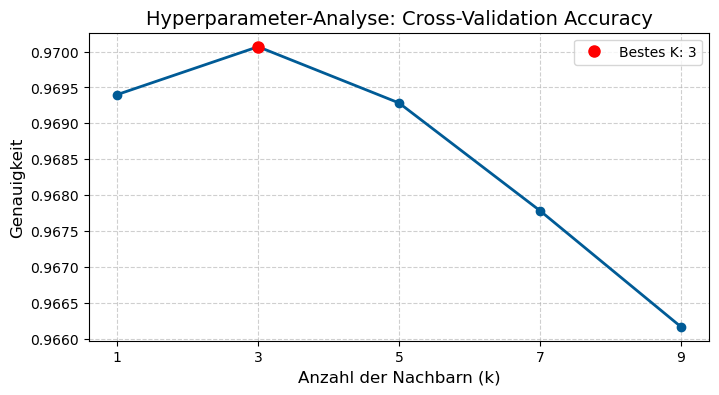

In [3]:
print("--- 2. Hyperparameter-Suche (Cross-Validation) ---")
print("Der Computer testet jetzt die besten k-Werte auf allen 60.000 Bildern.")
print("Das dauert jetzt ca. 5-10 Minuten. Zeit für einen Kaffee! ☕\n")

# Wir testen absichtlich nur ungerade Zahlen, um Unentschieden beim Voting zu vermeiden
k_liste =[1, 3, 5, 7, 9]
genauigkeiten_cv =[]

for k in k_liste:
    # n_jobs=-1 sagt dem PC, er soll alle Prozessorkerne nutzen (geht schneller!)
    temp_knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    
    start_zeit = time.time()
    
    # Die Kreuzvalidierung (5-Fold CV) - Verhindert Overfitting!
    scores = cross_val_score(temp_knn, x_train_flat, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    
    mittlere_genauigkeit = scores.mean()
    genauigkeiten_cv.append(mittlere_genauigkeit)
    dauer = time.time() - start_zeit
    
    print(f"Getestet: k={k:2d} | Genauigkeit: {mittlere_genauigkeit*100:.2f}% (± {scores.std()*100:.2f}%) | Dauer: {dauer:.2f} Sekunden")

# Den absoluten Gewinner automatisch herausfinden (statt ihn von Hand einzutragen)
bester_index = np.argmax(genauigkeiten_cv)
bestes_k = k_liste[bester_index]

print(f"\n=> Ergebnis: Das optimale k ist {bestes_k}!")

# Das Ergebnis als schöne Grafik zeichnen
plt.figure(figsize=(8, 4))
plt.plot(k_liste, genauigkeiten_cv, marker='o', linestyle='-', color='#005b96', linewidth=2)
plt.plot(bestes_k, genauigkeiten_cv[bester_index], 'ro', markersize=8, label=f'Bestes K: {bestes_k}')
plt.title("Hyperparameter-Analyse: Cross-Validation Accuracy", fontsize=14)
plt.xlabel("Anzahl der Nachbarn (k)", fontsize=12)
plt.ylabel("Genauigkeit", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(k_liste)
plt.legend()
plt.show()

Zelle 3: Das Finale Modell bauen

In [4]:
print(f"--- 3. Finales Modell trainieren (mit k={bestes_k}) ---")

# Wir übergeben unsere dynamische Variable 'bestes_k'
knn_final = KNeighborsClassifier(n_neighbors=bestes_k, n_jobs=-1)

print("Modell merkt sich die Trainingsdaten...")
start_final = time.time()
knn_final.fit(x_train_flat, y_train) 

print("Mache finale Vorhersage für die 10.000 Testbilder...")
vorhersagen_final = knn_final.predict(x_test_flat)
dauer_final = time.time() - start_final

acc_final = accuracy_score(y_test, vorhersagen_final)
print(f"Fertig in {dauer_final:.2f} Sekunden.")
print(f"🏆 FINALE GENAUIGKEIT: {acc_final * 100:.2f}%")

--- 3. Finales Modell trainieren (mit k=3) ---
Modell merkt sich die Trainingsdaten...
Mache finale Vorhersage für die 10.000 Testbilder...
Fertig in 2.74 Sekunden.
🏆 FINALE GENAUIGKEIT: 97.05%


Zelle 4: Report & Fehlersuche

--- 4. Classification Report ---
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      1.00      0.98      1135
           2       0.98      0.97      0.97      1032
           3       0.96      0.97      0.96      1010
           4       0.98      0.97      0.97       982
           5       0.97      0.96      0.96       892
           6       0.98      0.99      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.99      0.94      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000


--- 5. Optische Fehleranalyse ---
Von 10.000 Bildern wurden 295 falsch erkannt. Hier sind 4 Beispiele:


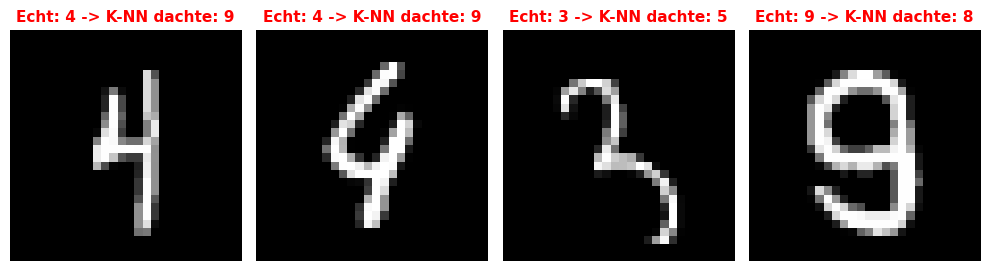

In [5]:
print("--- 4. Classification Report ---")
# Zeigt uns, wie gut spezielle Ziffern erkannt wurden (Vorschlag aus dem Peer-Feedback)
report = classification_report(y_test, vorhersagen_final, target_names=[str(i) for i in range(10)])
print(report)

print("\n--- 5. Optische Fehleranalyse ---")
# Wir filtern die Bilder heraus, bei denen das Modell sich geirrt hat
fehler_maske = vorhersagen_final != y_test
fehler_indizes = np.where(fehler_maske)[0]

print(f"Von 10.000 Bildern wurden {len(fehler_indizes)} falsch erkannt. Hier sind 4 Beispiele:")

plt.figure(figsize=(10, 3))
for i in range(min(4, len(fehler_indizes))):
    idx = fehler_indizes[i]
    
    # Wir brauchen das originale, un-flache Bild (28x28) für die Anzeige
    bild = x_test[idx] 
    echt = y_test[idx]
    geraten = vorhersagen_final[idx]
    
    plt.subplot(1, 4, i+1)
    plt.imshow(bild, cmap='gray')
    plt.title(f"Echt: {echt} -> K-NN dachte: {geraten}", color='red', fontsize=11, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

Zelle 5: Die blaue Confusion Matrix

--- 6. Confusion Matrix (Zusammenfassung der Fehler) ---


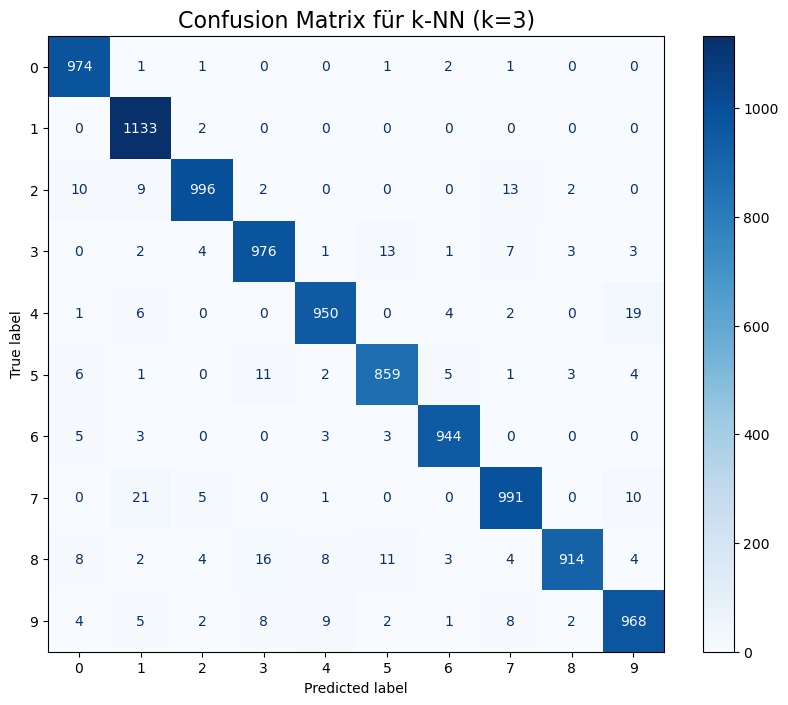

In [6]:
print("--- 6. Confusion Matrix (Zusammenfassung der Fehler) ---")

# Berechnet die Matrix
cm = confusion_matrix(y_test, vorhersagen_final)

# Zeichnet die Matrix (optisch passend zum Rest der Gruppe in Blau)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(ax=ax, cmap='Blues', values_format='d')

plt.title(f"Confusion Matrix für k-NN (k={bestes_k})", fontsize=16)
plt.show()

6. ROC Kurve 
Visualisierung der Klassifizierungsleistung für jede einzelne Ziffer.
Berechne Wahrscheinlichkeiten... (Das dauert einen kurzen Moment)


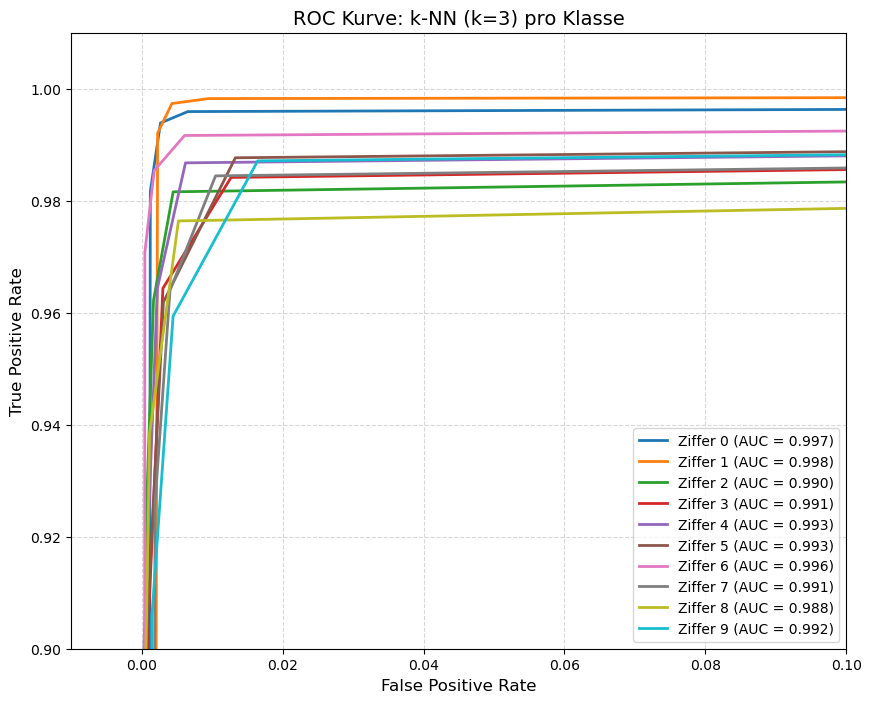

In [9]:
# ZELLE 6: ROC-KURVE (One-vs-Rest) 
print("6. ROC Kurve ")
print("Visualisierung der Klassifizierungsleistung für jede einzelne Ziffer.")
print("Berechne Wahrscheinlichkeiten... (Das dauert einen kurzen Moment)")

from sklearn.metrics import roc_curve, auc

# Wahrscheinlichkeiten für jede Klasse berechnen (Wichtig für ROC!)
Y_prob = knn_final.predict_proba(x_test_flat)

plt.figure(figsize=(10, 8))

# ROC-Kurve für jede Ziffer (0 bis 9) einzeln berechnen und plotten
for i in range(10):
    # Macht aus den 10 Ziffern ein Ja/Nein-Problem (z.B. "Ist es eine 3 oder nicht?")
    fpr, tpr, _ = roc_curve((y_test == i).astype(int), Y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"Ziffer {i} (AUC = {roc_auc:.3f})")

# Zufalls-Referenzlinie (gestrichelt) einzeichnen
plt.plot([0, 1],[0, 1], color="darkblue", lw=2, linestyle="--")

# Zoom auf den interessanten Bereich oben links (Genau wie Carolina es gemacht hat!)
plt.xlim([-0.01, 0.1]) 
plt.ylim([0.9, 1.01])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title(f"ROC Kurve: k-NN (k={bestes_k}) pro Klasse", fontsize=14)
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()